# BÀI TOÁN 8: APPLIANCES ENERGY PREDICTION

## 1. Giới thiệu

Đề tài thực hiện phân tích và tiền xử lý dữ liệu nhằm phục vụ bài toán dự đoán mức tiêu thụ năng lượng của các thiết bị điện trong gia đình.

Bộ dữ liệu được sử dụng là Appliances Energy Prediction, được thu thập từ UCI Machine Learning Repository.

Mục tiêu của phần thực hiện này là khám phá đặc điểm dữ liệu, phân tích các yếu tố liên quan đến mức tiêu thụ năng lượng, phát hiện dữ liệu bất thường và xây dựng các đặc trưng mới phục vụ mô hình học máy.

## 2. Thông tin bộ dữ liệu

- Tên bộ dữ liệu: Appliances Energy Prediction.
- Nguồn: UCI Machine Learning Repository.
- Số lượng mẫu ban đầu: 19.735.
- Số lượng thuộc tính ban đầu: 29 cột, bao gồm biến mục tiêu.
- Khoảng thời gian ghi nhận: 10 phút/lần.
- Biến mục tiêu: Appliances.
- Đơn vị: Wh.
- Loại bài toán: Regression.

Nguồn dữ liệu: https://archive.ics.uci.edu/dataset/374/appliances+energy+prediction

## 3. Phạm vi thực hiện

Phần A tập trung vào:
- Thu thập và đọc dữ liệu.
- Khám phá dữ liệu (EDA).
- Trực quan hóa dữ liệu.
- Kiểm tra dữ liệu thiếu, trùng lặp và ngoại lai.
- Tạo đặc trưng mới (Feature Engineering).
- Tiền xử lý và xuất dữ liệu phục vụ xây dựng mô hình.

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns 

In [3]:
df = pd.read_csv("../Data/raw/energydata_complete.csv")
df.head()

,date,Appliances,lights,T1,RH_1,T2,RH_2,T3,RH_3,T4,...,T9,RH_9,T_out,Press_mm_hg,RH_out,Windspeed,Visibility,Tdewpoint,rv1,rv2
0,2016-01-11 17:00:00,60,30,19.89,47.596667,19.2,44.790000,19.79,44.730000,19.000000,...,17.033333,45.53,6.600000,733.5,92.0,7.000000,63.000000,5.3,13.275433,13.275433
1,2016-01-11 17:10:00,60,30,19.89,46.693333,19.2,44.722500,19.79,44.790000,19.000000,...,17.066667,45.56,6.483333,733.6,92.0,6.666667,59.166667,5.2,18.606195,18.606195
2,2016-01-11 17:20:00,50,30,19.89,46.300000,19.2,44.626667,19.79,44.933333,18.926667,...,17.000000,45.50,6.366667,733.7,92.0,6.333333,55.333333,5.1,28.642668,28.642668
3,2016-01-11 17:30:00,50,40,19.89,46.066667,19.2,44.590000,19.79,45.000000,18.890000,...,17.000000,45.40,6.250000,733.8,92.0,6.000000,51.500000,5.0,45.410389,45.410389
4,2016-01-11 17:40:00,60,40,19.89,46.333333,19.2,44.530000,19.79,45.000000,18.890000,...,17.000000,45.40,6.133333,733.9,92.0,5.666667,47.666667,4.9,10.084097,10.084097


In [4]:
print("số dòng và cột: ", df.shape)
df.info()
df.describe()

số dòng và cột:  (19735, 29)
<class 'pandas.DataFrame'>
RangeIndex: 19735 entries, 0 to 19734
Data columns (total 29 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   date         19735 non-null  str    
 1   Appliances   19735 non-null  int64  
 2   lights       19735 non-null  int64  
 3   T1           19735 non-null  float64
 4   RH_1         19735 non-null  float64
 5   T2           19735 non-null  float64
 6   RH_2         19735 non-null  float64
 7   T3           19735 non-null  float64
 8   RH_3         19735 non-null  float64
 9   T4           19735 non-null  float64
 10  RH_4         19735 non-null  float64
 11  T5           19735 non-null  float64
 12  RH_5         19735 non-null  float64
 13  T6           19735 non-null  float64
 14  RH_6         19735 non-null  float64
 15  T7           19735 non-null  float64
 16  RH_7         19735 non-null  float64
 17  T8           19735 non-null  float64
 18  RH_8         19735 non-null 

,Appliances,lights,T1,RH_1,T2,RH_2,T3,RH_3,T4,RH_4,...,T9,RH_9,T_out,Press_mm_hg,RH_out,Windspeed,Visibility,Tdewpoint,rv1,rv2
count,19735.000000,19735.000000,19735.000000,19735.000000,19735.000000,19735.000000,19735.000000,19735.000000,19735.000000,19735.000000,...,19735.000000,19735.000000,19735.000000,19735.000000,19735.000000,19735.000000,19735.000000,19735.000000,19735.000000,19735.000000
mean,97.694958,3.801875,21.686571,40.259739,20.341219,40.420420,22.267611,39.242500,20.855335,39.026904,...,19.485828,41.552401,7.411665,755.522602,79.750418,4.039752,38.330834,3.760707,24.988033,24.988033
std,102.524891,7.935988,1.606066,3.979299,2.192974,4.069813,2.006111,3.254576,2.042884,4.341321,...,2.014712,4.151497,5.317409,7.399441,14.901088,2.451221,11.794719,4.194648,14.496634,14.496634
min,10.000000,0.000000,16.790000,27.023333,16.100000,20.463333,17.200000,28.766667,15.100000,27.660000,...,14.890000,29.166667,-5.000000,729.300000,24.000000,0.000000,1.000000,-6.600000,0.005322,0.005322
25%,50.000000,0.000000,20.760000,37.333333,18.790000,37.900000,20.790000,36.900000,19.530000,35.530000,...,18.000000,38.500000,3.666667,750.933333,70.333333,2.000000,29.000000,0.900000,12.497889,12.497889
50%,60.000000,0.000000,21.600000,39.656667,20.000000,40.500000,22.100000,38.530000,20.666667,38.400000,...,19.390000,40.900000,6.916667,756.100000,83.666667,3.666667,40.000000,3.433333,24.897653,24.897653
75%,100.000000,0.000000,22.600000,43.066667,21.500000,43.260000,23.290000,41.760000,22.100000,42.156667,...,20.600000,44.338095,10.408333,760.933333,91.666667,5.500000,40.000000,6.566667,37.583769,37.583769
max,1080.000000,70.000000,26.260000,63.360000,29.856667,56.026667,29.236000,50.163333,26.200000,51.090000,...,24.500000,53.326667,26.100000,772.300000,100.000000,14.000000,66.000000,15.500000,49.996530,49.996530


In [5]:
# Kiểm tra dữ liệu bị thiếu
print("số lượng dữ liệu bị thiếu: ", df.isnull().sum())
# Tổng số lượng dữ liệu bị thiếu
print("tổng số lượng bị thiếu: ",df.isnull().sum().sum())
# Kiểm tra số dòng trùng lặp
print("số dòng trùng lặp: ", df.duplicated().sum())

số lượng dữ liệu bị thiếu:  date           0
Appliances     0
lights         0
T1             0
RH_1           0
T2             0
RH_2           0
T3             0
RH_3           0
T4             0
RH_4           0
T5             0
RH_5           0
T6             0
RH_6           0
T7             0
RH_7           0
T8             0
RH_8           0
T9             0
RH_9           0
T_out          0
Press_mm_hg    0
RH_out         0
Windspeed      0
Visibility     0
Tdewpoint      0
rv1            0
rv2            0
dtype: int64
tổng số lượng bị thiếu:  0
số dòng trùng lặp:  0


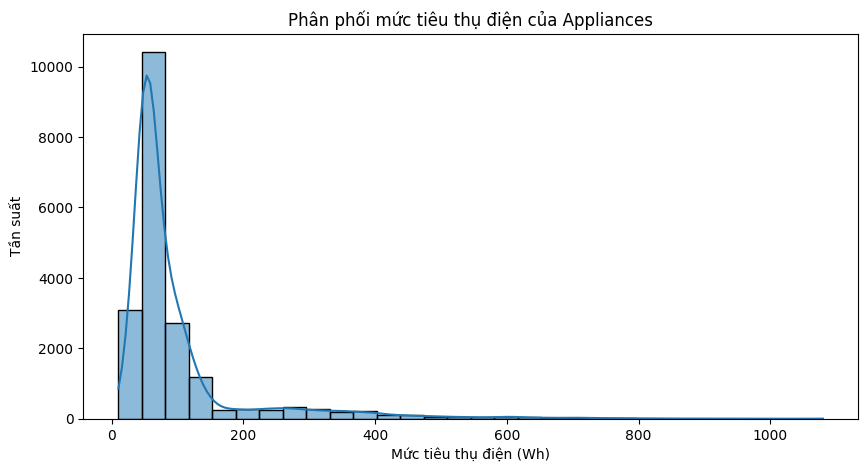

In [6]:
plt.figure(figsize=(10, 5))
sns.histplot(df["Appliances"], bins=30, kde=True)
plt.title("Phân phối mức tiêu thụ điện của Appliances")
plt.xlabel("Mức tiêu thụ điện (Wh)")
plt.ylabel("Tần suất")
plt.savefig("../images/appliances_distribution.png", dpi=300, bbox_inches='tight')
plt.show()

**Nhận xét:**

- Mức tiêu thụ điện của các thiết bị tập trung chủ yếu trong khoảng giá trị thấp, đặc biệt khoảng 0–150 Wh.
- Tần suất xuất hiện cao nhất nằm ở nhóm mức tiêu thụ khoảng 50–100 Wh.
- Khi mức tiêu thụ điện tăng lên, tần suất xuất hiện giảm dần.
- Phân phối dữ liệu có dạng lệch phải: một số ít trường hợp có mức tiêu thụ điện rất cao, vượt 500 Wh, thậm chí trên 1.000 Wh.
- Điều này cho thấy mức tiêu thụ điện không phân bố đồng đều và có thể tồn tại các giá trị cực lớn cần được xem xét khi xây dựng mô hình hồi quy.

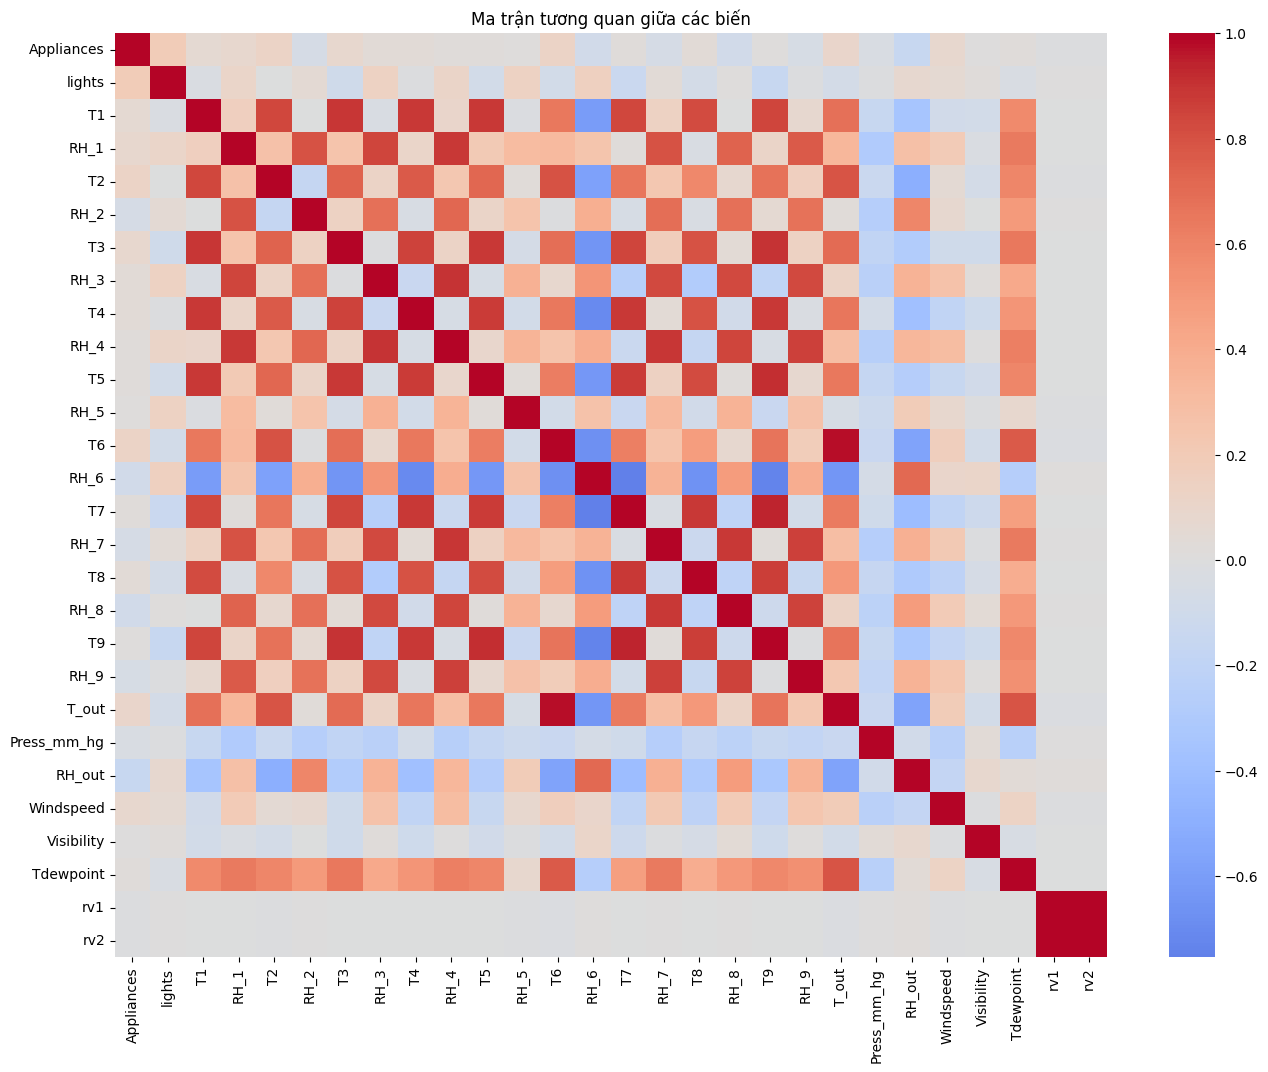

In [7]:
plt.figure(figsize=(16, 12))
corr = df.select_dtypes(include="number").corr()
sns.heatmap(corr, cmap="coolwarm", center=0)
plt.title("Ma trận tương quan giữa các biến")
plt.savefig("../images/correlation_heatmap.png", dpi=300, bbox_inches='tight')
plt.show()

**Nhận xét:**

- Ma trận tương quan cho thấy mối quan hệ giữa các thuộc tính trong bộ dữ liệu.
- Các biến nhiệt độ trong nhà có xu hướng tương quan dương với nhau.
- Một số biến độ ẩm cũng có mối tương quan với nhau.
- Màu đỏ biểu thị tương quan dương, màu xanh biểu thị tương quan âm; màu càng đậm thì mức độ tương quan càng lớn về trị tuyệt đối.
- Một số biến có tương quan mạnh với nhau, cho thấy có thể tồn tại hiện tượng đa cộng tuyến khi xây dựng mô hình hồi quy.
- Biểu đồ giúp nhận biết mối liên hệ giữa các thuộc tính và hỗ trợ lựa chọn đặc trưng phù hợp cho mô hình.

In [8]:
# Chuyển cột date sang kiểu datetime
df["date"]=pd.to_datetime(df["date"])
# Sắp xếp dữ liệu theo thời gian
df = df.sort_values("date")
# Kiểm tra
print(df["date"].dtype)
print(df[["date","Appliances"]].head())

datetime64[us]
                 date  Appliances
0 2016-01-11 17:00:00          60
1 2016-01-11 17:10:00          60
2 2016-01-11 17:20:00          50
3 2016-01-11 17:30:00          50
4 2016-01-11 17:40:00          60


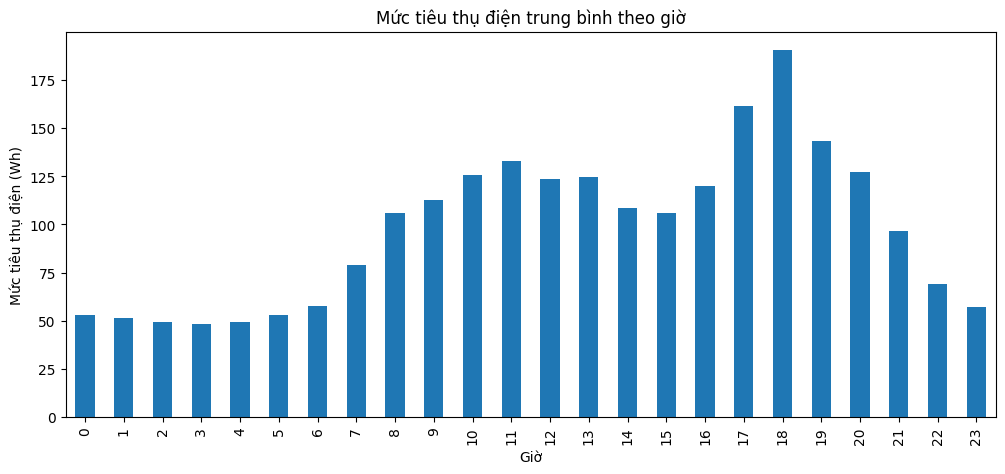

In [9]:
# Tạo cột giờ
df["hour"]=df["date"].dt.hour
# Tính mức tiêu thụ điện trung bình theo giờ
energy_by_hour = df.groupby("hour")["Appliances"].mean()
plt.figure(figsize= (12, 5))
energy_by_hour.plot(kind="bar")
plt.title("Mức tiêu thụ điện trung bình theo giờ")  
plt.xlabel("Giờ")
plt.ylabel("Mức tiêu thụ điện (Wh)")
plt.savefig("../images/energy_by_hour.png", dpi=300, bbox_inches='tight')
plt.show()

**Nhận xét:**

- Mức tiêu thụ điện trung bình của các thiết bị có sự thay đổi theo từng khung giờ trong ngày.
- Trong khoảng 0–6 giờ, mức tiêu thụ điện tương đối thấp và ổn định.
- Từ 7 giờ đến 11 giờ, mức tiêu thụ điện tăng dần.
- Trong khoảng 17–19 giờ, mức tiêu thụ điện tăng mạnh và đạt mức cao nhất vào khoảng 18 giờ.
- Sau 19 giờ, mức tiêu thụ điện có xu hướng giảm dần.
- Điều này cho thấy thời điểm trong ngày có thể là một yếu tố ảnh hưởng đến mức tiêu thụ điện của các thiết bị.

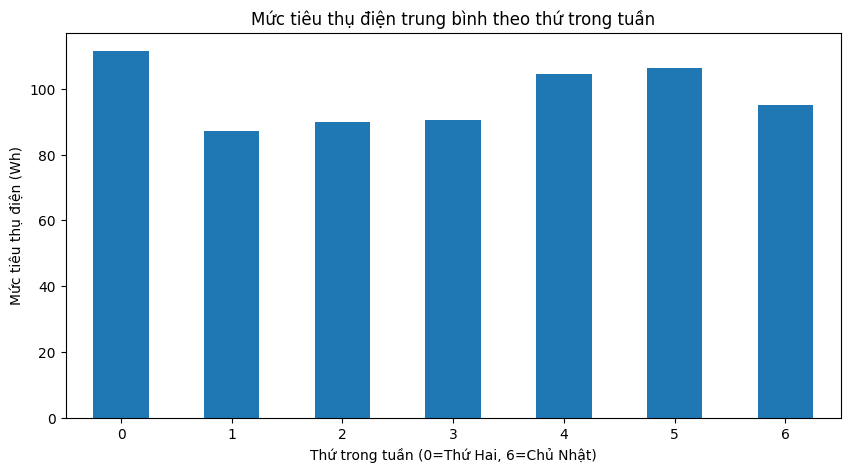

In [10]:
# Tạo cột thứ trong tuần
df["day_of_week"] = df["date"].dt.dayofweek
# Tính mức tiêu thụ điện trung bình theo thứ trong tuần
energy_by_day = df.groupby("day_of_week")["Appliances"].mean()
plt.figure(figsize= (10, 5))
energy_by_day.plot(kind="bar")
plt.title("Mức tiêu thụ điện trung bình theo thứ trong tuần")
plt.xlabel("Thứ trong tuần (0=Thứ Hai, 6=Chủ Nhật)")
plt.ylabel("Mức tiêu thụ điện (Wh)")
plt.xticks(rotation=0)
plt.savefig("../images/energy_by_day.png", dpi=300, bbox_inches='tight')
plt.show()


**Nhận xét:**

- Mức tiêu thụ điện trung bình có sự khác nhau giữa các ngày trong tuần.
- Thứ Hai có mức tiêu thụ điện trung bình cao nhất, khoảng 111 Wh.
- Thứ Ba có mức tiêu thụ thấp nhất, khoảng 87 Wh.
- Mức tiêu thụ điện vào Thứ Sáu và Thứ Bảy tương đối cao, lần lượt khoảng 104 Wh và 106 Wh.
- Chủ Nhật có mức tiêu thụ khoảng 95 Wh.
- Nhìn chung, mức tiêu thụ điện thay đổi theo từng ngày nhưng không có sự chênh lệch quá lớn giữa các ngày.
- Điều này cho thấy thứ trong tuần có thể là một đặc trưng hữu ích khi dự đoán mức tiêu thụ điện.

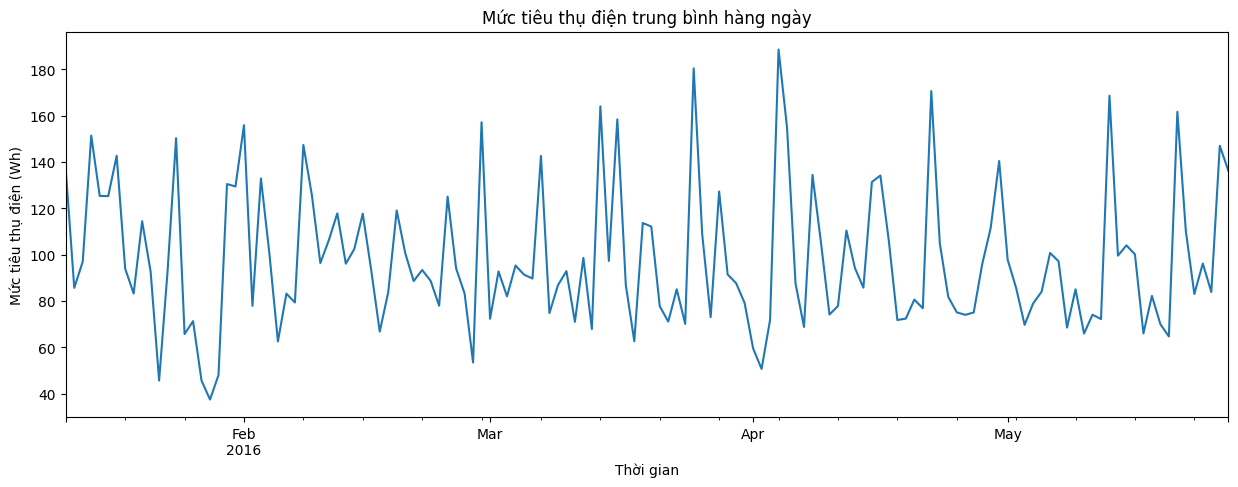

In [11]:
# Đặt date làm chỉ mục thời gian
daily_energy = df.set_index("date")["Appliances"].resample("D").mean()
plt.figure(figsize=(15, 5))
daily_energy.plot()
plt.title("Mức tiêu thụ điện trung bình hàng ngày") 
plt.xlabel("Thời gian")
plt.ylabel("Mức tiêu thụ điện (Wh)")
plt.savefig("../images/daily_energy.png", dpi=300, bbox_inches='tight')
plt.show()    

**Nhận xét:**

- Mức tiêu thụ điện trung bình hằng ngày có sự biến động đáng kể theo thời gian.
- Phần lớn các ngày có mức tiêu thụ nằm trong khoảng 60–130 Wh.
- Một số ngày xuất hiện mức tiêu thụ cao, khoảng 160–190 Wh, trong khi một số ngày giảm xuống dưới 50 Wh.
- Mức tiêu thụ điện không duy trì xu hướng tăng hoặc giảm liên tục mà thay đổi qua từng ngày.
- Điều này cho thấy mức tiêu thụ điện có sự biến động theo thời gian và yếu tố thời gian có thể hữu ích trong việc xây dựng mô hình dự đoán.

In [12]:
Q1 = df["Appliances"].quantile(0.25)
Q3 = df["Appliances"].quantile(0.75)
IQR = Q3 - Q1
lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR
outliers = df[(df["Appliances"] < lower_bound) | (df["Appliances"] > upper_bound)]
print("Ngưỡng dưới: ", lower_bound)
print("Ngưỡng trên: ", upper_bound)
print("Số lượng giá trị ngoại lệ: ", len(outliers)) 

Ngưỡng dưới:  -25.0
Ngưỡng trên:  175.0
Số lượng giá trị ngoại lệ:  2138


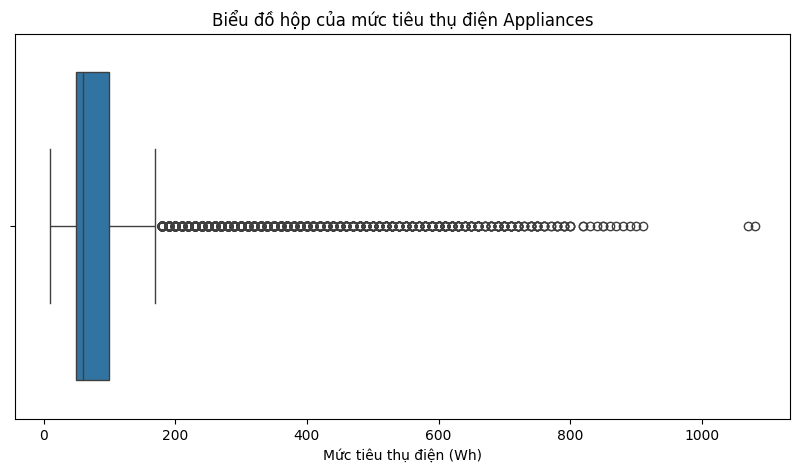

In [13]:
plt.figure(figsize=(10, 5))
sns.boxplot(x=df["Appliances"])
plt.title("Biểu đồ hộp của mức tiêu thụ điện Appliances")
plt.xlabel("Mức tiêu thụ điện (Wh)")
plt.savefig("../images/appliances_boxplot.png", dpi=300, bbox_inches='tight')
plt.show()

**Nhận xét:**

- Biểu đồ hộp cho thấy phần lớn mức tiêu thụ điện của thiết bị tập trung trong khoảng giá trị thấp.
- Xuất hiện nhiều điểm nằm ngoài phạm vi hai đầu râu của biểu đồ, đặc biệt ở phía mức tiêu thụ điện cao.
- Một số giá trị ngoại lệ vượt 800 Wh và có trường hợp vượt 1.000 Wh.
- Điều này cho thấy dữ liệu có sự phân bố lệch phải và tồn tại một số thời điểm tiêu thụ điện rất cao.
- Các giá trị ngoại lệ chưa bị loại bỏ vì chúng có thể phản ánh mức tiêu thụ điện thực tế. Cần cân nhắc khi xây dựng mô hình hồi quy để tránh làm mất thông tin có ích.

In [14]:
# Xác định ngày cuối tuần
df["is_weekend"] = ( df["date"].dt.dayofweek >= 5 ).astype(int)
df[["date", "day_of_week", "is_weekend"]].head(10)

,date,day_of_week,is_weekend
0,2016-01-11 17:00:00,0,0
1,2016-01-11 17:10:00,0,0
2,2016-01-11 17:20:00,0,0
3,2016-01-11 17:30:00,0,0
4,2016-01-11 17:40:00,0,0
5,2016-01-11 17:50:00,0,0
6,2016-01-11 18:00:00,0,0
7,2016-01-11 18:10:00,0,0
8,2016-01-11 18:20:00,0,0
9,2016-01-11 18:30:00,0,0


In [15]:
# Lấy giá trị Appliances của lần đo trước
df["lag_1"] = df["Appliances"].shift(1)
df[["date", "Appliances", "lag_1"]].head(10)

,date,Appliances,lag_1
0,2016-01-11 17:00:00,60,NaN
1,2016-01-11 17:10:00,60,60.0
2,2016-01-11 17:20:00,50,60.0
3,2016-01-11 17:30:00,50,50.0
4,2016-01-11 17:40:00,60,50.0
5,2016-01-11 17:50:00,50,60.0
6,2016-01-11 18:00:00,60,50.0
7,2016-01-11 18:10:00,60,60.0
8,2016-01-11 18:20:00,60,60.0
9,2016-01-11 18:30:00,70,60.0


In [16]:
# Tính trung bình 3 lần đo trước
df["rolling_mean"] = ( df["Appliances"].shift(1).rolling(window=3).mean())
df[["date", "Appliances", "rolling_mean"]].head(10)

,date,Appliances,rolling_mean
0,2016-01-11 17:00:00,60,NaN
1,2016-01-11 17:10:00,60,NaN
2,2016-01-11 17:20:00,50,NaN
3,2016-01-11 17:30:00,50,56.666667
4,2016-01-11 17:40:00,60,53.333333
5,2016-01-11 17:50:00,50,53.333333
6,2016-01-11 18:00:00,60,53.333333
7,2016-01-11 18:10:00,60,56.666667
8,2016-01-11 18:20:00,60,56.666667
9,2016-01-11 18:30:00,70,60.000000


In [17]:
print("Kích thước dữ liệu: ", df.shape)
print("\nCác cột trong dữ liệu:")
print(df[["hour", "day_of_week", "is_weekend", "lag_1", "rolling_mean"]].head(10))

Kích thước dữ liệu:  (19735, 34)

Các cột trong dữ liệu:
   hour  day_of_week  is_weekend  lag_1  rolling_mean
0    17            0           0    NaN           NaN
1    17            0           0   60.0           NaN
2    17            0           0   60.0           NaN
3    17            0           0   50.0     56.666667
4    17            0           0   50.0     53.333333
5    17            0           0   60.0     53.333333
6    18            0           0   50.0     53.333333
7    18            0           0   60.0     56.666667
8    18            0           0   60.0     56.666667
9    18            0           0   60.0     60.000000


In [18]:
# Kiểm tra dữ liệu thiếu sau khi tạo đặc trưng
print("Số lượng giá trị thiếu:")
print(df.isnull().sum())
print("\nTổng số lượng giá trị thiếu: ")
print(df.isnull().sum().sum())

Số lượng giá trị thiếu:
date            0
Appliances      0
lights          0
T1              0
RH_1            0
T2              0
RH_2            0
T3              0
RH_3            0
T4              0
RH_4            0
T5              0
RH_5            0
T6              0
RH_6            0
T7              0
RH_7            0
T8              0
RH_8            0
T9              0
RH_9            0
T_out           0
Press_mm_hg     0
RH_out          0
Windspeed       0
Visibility      0
Tdewpoint       0
rv1             0
rv2             0
hour            0
day_of_week     0
is_weekend      0
lag_1           1
rolling_mean    3
dtype: int64

Tổng số lượng giá trị thiếu: 
4


In [19]:
# Loại bỏ các dòng chưa có đủ dữ liệu quá khứ
df = df.dropna(
    subset=["lag_1", "rolling_mean"]
).copy()
# Kiểm tra lại
print("Kích thước sau xử lý: ", df.shape)
print("Tổng giá trị thiếu: ", df.isnull().sum().sum())

Kích thước sau xử lý:  (19732, 34)
Tổng giá trị thiếu:  0


In [20]:
# Hiển thị 5 dòng đầu tiên
display(df.head())
# Kiểm tra thông tin dữ liệu
df.info()
# Kiểm tra thống kê
df.describe()

,date,Appliances,lights,T1,RH_1,T2,RH_2,T3,RH_3,T4,...,Windspeed,Visibility,Tdewpoint,rv1,rv2,hour,day_of_week,is_weekend,lag_1,rolling_mean
3,2016-01-11 17:30:00,50,40,19.890000,46.066667,19.2,44.59,19.79,45.000000,18.89,...,6.000000,51.500000,5.000000,45.410389,45.410389,17,0,0,50.0,56.666667
4,2016-01-11 17:40:00,60,40,19.890000,46.333333,19.2,44.53,19.79,45.000000,18.89,...,5.666667,47.666667,4.900000,10.084097,10.084097,17,0,0,50.0,53.333333
5,2016-01-11 17:50:00,50,40,19.890000,46.026667,19.2,44.50,19.79,44.933333,18.89,...,5.333333,43.833333,4.800000,44.919484,44.919484,17,0,0,60.0,53.333333
6,2016-01-11 18:00:00,60,50,19.890000,45.766667,19.2,44.50,19.79,44.900000,18.89,...,5.000000,40.000000,4.700000,47.233763,47.233763,18,0,0,50.0,53.333333
7,2016-01-11 18:10:00,60,50,19.856667,45.560000,19.2,44.50,19.73,44.900000,18.89,...,5.166667,40.000000,4.683333,33.039890,33.039890,18,0,0,60.0,56.666667


<class 'pandas.DataFrame'>
RangeIndex: 19732 entries, 3 to 19734
Data columns (total 34 columns):
 #   Column        Non-Null Count  Dtype         
---  ------        --------------  -----         
 0   date          19732 non-null  datetime64[us]
 1   Appliances    19732 non-null  int64         
 2   lights        19732 non-null  int64         
 3   T1            19732 non-null  float64       
 4   RH_1          19732 non-null  float64       
 5   T2            19732 non-null  float64       
 6   RH_2          19732 non-null  float64       
 7   T3            19732 non-null  float64       
 8   RH_3          19732 non-null  float64       
 9   T4            19732 non-null  float64       
 10  RH_4          19732 non-null  float64       
 11  T5            19732 non-null  float64       
 12  RH_5          19732 non-null  float64       
 13  T6            19732 non-null  float64       
 14  RH_6          19732 non-null  float64       
 15  T7            19732 non-null  float64       
 1

,date,Appliances,lights,T1,RH_1,T2,RH_2,T3,RH_3,T4,...,Windspeed,Visibility,Tdewpoint,rv1,rv2,hour,day_of_week,is_weekend,lag_1,rolling_mean
count,19732,19732.000000,19732.000000,19732.000000,19732.000000,19732.000000,19732.000000,19732.000000,19732.000000,19732.000000,...,19732.000000,19732.000000,19732.000000,19732.000000,19732.000000,19732.000000,19732.000000,19732.000000,19732.000000,19732.000000
mean,2016-03-20 05:45:00,97.701196,3.797892,21.686845,40.258735,20.341393,40.419768,22.267988,39.241652,20.855621,...,4.039352,38.327666,3.760488,24.988765,24.988765,11.501166,2.977701,0.277316,97.681938,97.666227
min,2016-01-11 17:30:00,10.000000,0.000000,16.790000,27.023333,16.100000,20.463333,17.200000,28.766667,15.100000,...,0.000000,1.000000,-6.600000,0.005322,0.005322,0.000000,0.000000,0.000000,10.000000,16.666667
25%,2016-02-14 23:37:30,50.000000,0.000000,20.760000,37.333333,18.790000,37.900000,20.790000,36.900000,19.533333,...,2.000000,29.000000,0.900000,12.495746,12.495746,6.000000,1.000000,0.000000,50.000000,50.000000
50%,2016-03-20 05:45:00,60.000000,0.000000,21.600000,39.656667,20.000000,40.500000,22.100000,38.530000,20.666667,...,3.666667,40.000000,3.433333,24.897709,24.897709,12.000000,3.000000,0.000000,60.000000,60.000000
75%,2016-04-23 11:52:30,100.000000,0.000000,22.600000,43.066667,21.500000,43.260000,23.290000,41.760000,22.100000,...,5.500000,40.000000,6.566667,37.586778,37.586778,17.250000,5.000000,1.000000,100.000000,103.333333
max,2016-05-27 18:00:00,1080.000000,70.000000,26.260000,63.360000,29.856667,56.026667,29.236000,50.163333,26.200000,...,14.000000,66.000000,15.500000,49.996530,49.996530,23.000000,6.000000,1.000000,1080.000000,850.000000
std,NaN,102.531420,7.930013,1.606035,3.978762,2.193095,4.069778,2.006030,3.254098,2.042908,...,2.451191,11.792754,4.194929,14.497402,14.497402,6.922147,1.985429,0.447685,102.504686,90.900983


In [21]:
# Lưu dữ liệu đã xử lý
df.to_csv("../Data/processed/appliances_processed.csv", index=False) 
print("Đã lưu dữ liệu")

Đã lưu dữ liệu


In [22]:
print("Kích thước:", df.shape)
print("Danh sách cột:")
print(df.columns.tolist())
print("Dữ liệu thiếu:", df.isnull().sum().sum())

Kích thước: (19732, 34)
Danh sách cột:
['date', 'Appliances', 'lights', 'T1', 'RH_1', 'T2', 'RH_2', 'T3', 'RH_3', 'T4', 'RH_4', 'T5', 'RH_5', 'T6', 'RH_6', 'T7', 'RH_7', 'T8', 'RH_8', 'T9', 'RH_9', 'T_out', 'Press_mm_hg', 'RH_out', 'Windspeed', 'Visibility', 'Tdewpoint', 'rv1', 'rv2', 'hour', 'day_of_week', 'is_weekend', 'lag_1', 'rolling_mean']
Dữ liệu thiếu: 0


In [23]:
# Xuất dữ liệu đã xử lý
df.to_csv(
    "../data/processed/appliances_processed.csv",
    index=False
)

print("Đã lưu dữ liệu thành công!")
print("Kích thước:", df.shape)

Đã lưu dữ liệu thành công!
Kích thước: (19732, 34)


## 4. Tổng kết quá trình EDA và tiền xử lý

### 4.1. Kết quả khám phá dữ liệu
- Đã tìm hiểu cấu trúc, số lượng mẫu và các thuộc tính của bộ dữ liệu.
- Đã kiểm tra giá trị thiếu và dữ liệu trùng lặp.
- Đã trực quan hóa phân phối mức tiêu thụ năng lượng của thiết bị.
- Đã phân tích mối tương quan giữa các thuộc tính.
- Đã khảo sát mức tiêu thụ năng lượng theo giờ, ngày trong tuần và theo thời gian.
- Đã sử dụng phương pháp IQR để kiểm tra các giá trị ngoại lệ của biến mục tiêu `Appliances`.

### 4.2. Kết quả tiền xử lý
- Chuyển đổi cột `date` sang kiểu dữ liệu thời gian.
- Sắp xếp dữ liệu theo thời gian.
- Tạo các đặc trưng `hour`, `day_of_week`, `is_weekend`, `lag_1` và `rolling_mean`.
- Loại bỏ 3 dòng đầu tiên phát sinh giá trị thiếu do tạo đặc trưng trễ và trung bình trượt.
- Xuất dữ liệu sau xử lý thành file `appliances_processed.csv`.

### 4.3. Kết quả dữ liệu sau xử lý
- Số dòng: 19.732.
- Số cột: 34.
- Số lượng giá trị thiếu sau xử lý: 0.

### 4.4. Những công việc chưa thực hiện
- Chưa tiến hành chia tập dữ liệu huấn luyện và kiểm tra.
- Chưa thực hiện chuẩn hóa dữ liệu.
- Chưa huấn luyện và đánh giá mô hình học máy.

Các công việc trên sẽ được phối hợp thực hiện trong giai đoạn xây dựng và đánh giá mô hình.